# 08 · Module Project — A Tested ETL Pipeline

**Module 01 — Python Foundations for Data Science**

---

## The brief

You have joined the data team at **Nordwind Retail**. Two systems export data
nightly, and neither is well behaved:

- `orders.csv` — the order management system. Latin-1 encoded, European decimal
  commas, inconsistent casing, `"N/A"` for nulls, and duplicate rows whenever a
  retry fires.
- `customers.json` — the CRM, as a nested API dump.

**Your job:** build a pipeline that turns these into one clean, typed,
analysis-ready Parquet table, and produce a short revenue readout from it.

It must be **defensive** (bad data fails loudly), **observable** (logged), and
**tested**.

## What this exercises

| Notebook | Concept used here |
| :--- | :--- |
| 02 | Immutability, float comparison, string cleaning, `nan` semantics |
| 03 | `set` lookups, `defaultdict`, comprehensions, sorting |
| 04 | Pure functions, keyword-only arguments, generators, decorators |
| 05 | `@dataclass` configuration, a class with fitted state |
| 06 | `pathlib`, context managers, encodings, CSV → Parquet |
| 07 | Custom exceptions, logging, validation, `pytest` |

**Estimated time:** 120 minutes

In [1]:
import json
import logging
import subprocess
import sys
import tempfile
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dstoolkit import format_bytes, setup_plot_style, timer
from dstoolkit.plotting import COLORS

setup_plot_style()

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(name)-22s | %(message)s",
    datefmt="%H:%M:%S",
    stream=sys.stdout,
    force=True,
)

logger = logging.getLogger("nordwind.pipeline")


def find_repo_root(marker: str = "pyproject.toml") -> Path:
    """Locate the project root by walking upward for a marker file."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"no {marker} found above {Path.cwd()}")


REPO_ROOT = find_repo_root()
RAW_DIR = REPO_ROOT / "data" / "raw"
PROCESSED_DIR = REPO_ROOT / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(f"project root : {REPO_ROOT}")

project root : /Users/usuario/Desktop/CoursePythonStatistics


## Step 0 — Generate the (deliberately messy) source data

In a real job this arrives from an upstream system. We synthesise it here so the
project is self-contained — and so the mess is reproducible.

In [2]:
def generate_raw_sources(*, n_orders: int = 5_000, seed: int = 42) -> tuple[Path, Path]:
    """Write the two messy source files and return their paths.

    Every defect below is one this course's author has met in production.
    """
    rng = np.random.default_rng(seed)

    customer_ids = np.arange(1000, 1000 + 800)

    orders = pd.DataFrame({
        "order_id": np.arange(1, n_orders + 1),
        "customer_id": rng.choice(customer_ids, size=n_orders),
        "order_date": pd.to_datetime("2024-01-01")
                      + pd.to_timedelta(rng.integers(0, 365, n_orders), unit="D"),
        # Defect 1: inconsistent casing and stray whitespace.
        "channel": rng.choice(
            ["Organic", "organic ", " PAID", "paid", "Referral", "email"],
            size=n_orders,
        ),
        "country": rng.choice(["BR", "br", "US", "us", "PT"], size=n_orders),
        "amount": np.round(rng.lognormal(4.0, 0.7, n_orders), 2),
        "quantity": rng.integers(1, 8, n_orders),
    })

    # Defect 2: some amounts are missing, encoded inconsistently.
    missing_idx = rng.choice(n_orders, size=int(n_orders * 0.03), replace=False)
    amount_str = orders["amount"].astype(str)
    for i, token in zip(missing_idx, rng.choice(["N/A", "", "-", "null"],
                                                size=len(missing_idx)), strict=True):
        amount_str.iloc[i] = token

    # Defect 3: European decimal comma instead of a point.
    orders["amount"] = amount_str.str.replace(".", ",", regex=False)

    # Defect 4: a handful of negative quantities (bad returns handling upstream).
    bad_qty_idx = rng.choice(n_orders, size=12, replace=False)
    orders.loc[bad_qty_idx, "quantity"] = -1

    # Defect 5: duplicated rows from retry logic.
    duplicates = orders.sample(n=int(n_orders * 0.02), random_state=seed)
    orders = pd.concat([orders, duplicates], ignore_index=True)

    # Defect 6: orders referencing customers that do not exist in the CRM.
    orphan_idx = rng.choice(len(orders), size=25, replace=False)
    orders.loc[orphan_idx, "customer_id"] = 999_999

    orders_path = RAW_DIR / "nordwind_orders.csv"
    # Defect 7: semicolon separator and Latin-1 encoding.
    orders.to_csv(orders_path, index=False, sep=";", encoding="latin-1")

    # --- The CRM export, as nested JSON ------------------------------------
    segments = ["consumer", "corporate", "home_office"]
    customers = {
        "exported_at": "2024-12-31T23:59:59Z",
        "records": [
            {
                "id": int(cid),
                "profile": {
                    "name": f"Customer {cid}",
                    "segment": str(rng.choice(segments)),
                },
                "location": {"country": str(rng.choice(["BR", "US", "PT"]))},
                "signup_date": str(
                    (pd.to_datetime("2020-01-01")
                     + pd.to_timedelta(int(rng.integers(0, 1400)), unit="D")).date()
                ),
            }
            for cid in customer_ids
        ],
    }

    customers_path = RAW_DIR / "nordwind_customers.json"
    with customers_path.open("w", encoding="utf-8") as f:
        json.dump(customers, f, indent=2)

    return orders_path, customers_path


ORDERS_PATH, CUSTOMERS_PATH = generate_raw_sources()

print(f"orders    : {ORDERS_PATH.name}  ({format_bytes(ORDERS_PATH.stat().st_size)})")
print(f"customers : {CUSTOMERS_PATH.name}  ({format_bytes(CUSTOMERS_PATH.stat().st_size)})")

orders    : nordwind_orders.csv  (193.8 KiB)
customers : nordwind_customers.json  (164.4 KiB)


In [3]:
# Look at the raw bytes before assuming anything. This habit catches encoding and
# separator problems in ten seconds instead of thirty minutes.
with ORDERS_PATH.open("rb") as f:
    head = f.read(220)

print("raw bytes:")
print(head)
print("\ndecoded as latin-1:")
print(head.decode("latin-1"))

raw bytes:
b'order_id;customer_id;order_date;channel;country;amount;quantity\n1;1071;2024-03-13; PAID;BR;14,61;4\n2;1619;2024-01-13;organic ;US;120,46;6\n3;1523;2024-08-16;paid;US;124,95;6\n4;1351;2024-09-06;paid;us;39,17;4\n5;1346;2024-1'

decoded as latin-1:
order_id;customer_id;order_date;channel;country;amount;quantity
1;1071;2024-03-13; PAID;BR;14,61;4
2;1619;2024-01-13;organic ;US;120,46;6
3;1523;2024-08-16;paid;US;124,95;6
4;1351;2024-09-06;paid;us;39,17;4
5;1346;2024-1


## Step 1 — The contract

Before writing any transformation, state what "clean" means. Encoding the
contract as a `@dataclass` makes it explicit, testable, and easy to change in
one place.

In [4]:
@dataclass(frozen=True)
class PipelineConfig:
    """Immutable configuration for one pipeline run.

    Frozen so no step can quietly rewrite a setting halfway through.
    """

    orders_path: Path
    customers_path: Path
    output_path: Path

    # Business rules, named rather than scattered as magic numbers.
    min_amount: float = 0.01
    max_amount: float = 100_000.0
    valid_channels: frozenset[str] = frozenset(
        {"organic", "paid", "referral", "email"}
    )
    # A run fails outright if more than this share of rows is unusable.
    max_reject_rate: float = 0.10

    def __post_init__(self) -> None:
        if not 0 <= self.max_reject_rate <= 1:
            raise ValueError("max_reject_rate must be between 0 and 1")


@dataclass
class PipelineReport:
    """Mutable record of what happened during a run — for observability."""

    rows_read: int = 0
    duplicates_removed: int = 0
    unparseable_amounts: int = 0
    invalid_quantities: int = 0
    out_of_range_amounts: int = 0
    orphan_orders: int = 0
    rows_written: int = 0
    rejections: dict[str, int] = field(default_factory=dict)

    @property
    def reject_rate(self) -> float:
        """Share of input rows that did not survive cleaning."""
        if self.rows_read == 0:
            return 0.0
        return 1 - (self.rows_written / self.rows_read)

    def summary(self) -> pd.DataFrame:
        """Render the report as a readable table."""
        return pd.DataFrame(
            [
                ("rows read", self.rows_read),
                ("duplicates removed", self.duplicates_removed),
                ("unparseable amounts", self.unparseable_amounts),
                ("invalid quantities", self.invalid_quantities),
                ("out-of-range amounts", self.out_of_range_amounts),
                ("orphan customer refs", self.orphan_orders),
                ("rows written", self.rows_written),
            ],
            columns=["stage", "rows"],
        ).set_index("stage")


CONFIG = PipelineConfig(
    orders_path=ORDERS_PATH,
    customers_path=CUSTOMERS_PATH,
    output_path=PROCESSED_DIR / "nordwind_orders_clean.parquet",
)

print(CONFIG)

PipelineConfig(orders_path=PosixPath('/Users/usuario/Desktop/CoursePythonStatistics/data/raw/nordwind_orders.csv'), customers_path=PosixPath('/Users/usuario/Desktop/CoursePythonStatistics/data/raw/nordwind_customers.json'), output_path=PosixPath('/Users/usuario/Desktop/CoursePythonStatistics/data/processed/nordwind_orders_clean.parquet'), min_amount=0.01, max_amount=100000.0, valid_channels=frozenset({'paid', 'organic', 'email', 'referral'}), max_reject_rate=0.1)


## Step 2 — Domain exceptions

A shared base class lets a caller catch every pipeline failure at once, while
still allowing specific handling where it matters (notebook 07).

In [5]:
class PipelineError(Exception):
    """Base class for every failure this pipeline can raise."""


class SourceReadError(PipelineError):
    """A source file is missing, unreadable, or in the wrong format."""


class SchemaError(PipelineError):
    """A source file does not have the expected columns."""

    def __init__(self, source: str, missing: set[str], available: set[str]) -> None:
        self.missing = missing
        super().__init__(
            f"{source}: missing column(s) {sorted(missing)}; "
            f"found {sorted(available)}"
        )


class DataQualityError(PipelineError):
    """Too much of the input was unusable to trust the output."""

## Step 3 — Extract

Read the sources, validate their shape immediately, and log what happened. Note
that these functions are the **impure shell**: they touch the filesystem. Every
function after this one is pure.

In [6]:
EXPECTED_ORDER_COLUMNS = {
    "order_id", "customer_id", "order_date", "channel",
    "country", "amount", "quantity",
}


def extract_orders(config: PipelineConfig) -> pd.DataFrame:
    """Read the raw orders CSV, handling its encoding and separator quirks."""
    log = logging.getLogger("nordwind.extract")

    if not config.orders_path.exists():
        raise SourceReadError(f"orders file not found: {config.orders_path}")

    try:
        df = pd.read_csv(
            config.orders_path,
            sep=";",
            encoding="latin-1",
            # Read everything as a string. We would rather do the type
            # conversion ourselves, explicitly, than let pandas guess and
            # silently coerce "N/A" into something unexpected.
            dtype=str,
        )
    except UnicodeDecodeError as exc:
        raise SourceReadError(
            f"{config.orders_path.name} is not latin-1 encoded"
        ) from exc
    except pd.errors.EmptyDataError as exc:
        raise SourceReadError(f"{config.orders_path.name} is empty") from exc

    missing = EXPECTED_ORDER_COLUMNS - set(df.columns)
    if missing:
        raise SchemaError("orders.csv", missing, set(df.columns))

    log.info("Read %d raw order rows", len(df))
    return df


def extract_customers(config: PipelineConfig) -> pd.DataFrame:
    """Read and flatten the nested CRM export."""
    log = logging.getLogger("nordwind.extract")

    if not config.customers_path.exists():
        raise SourceReadError(f"customers file not found: {config.customers_path}")

    with config.customers_path.open(encoding="utf-8") as f:
        payload = json.load(f)

    if "records" not in payload:
        raise SchemaError("customers.json", {"records"}, set(payload))

    # json_normalize flattens `profile.segment` → a `profile.segment` column.
    customers = pd.json_normalize(payload["records"])
    customers.columns = [c.replace(".", "_") for c in customers.columns]

    log.info("Read %d customer records (exported %s)",
             len(customers), payload.get("exported_at", "unknown"))
    return customers


with timer("extract"):
    raw_orders = extract_orders(CONFIG)
    raw_customers = extract_customers(CONFIG)

print()
raw_orders.head(3)

13:07:19 | INFO     | nordwind.extract       | Read 5100 raw order rows


13:07:19 | INFO     | nordwind.extract       | Read 800 customer records (exported 2024-12-31T23:59:59Z)


extract: 0.0210 s



,order_id,customer_id,order_date,channel,country,amount,quantity
0,1,1071,2024-03-13,PAID,BR,"14,61",4
1,2,1619,2024-01-13,organic,US,"120,46",6
2,3,1523,2024-08-16,paid,US,"124,95",6


In [7]:
raw_customers.head(3)

,id,signup_date,profile_name,profile_segment,location_country
0,1000,2020-10-27,Customer 1000,home_office,BR
1,1001,2021-11-26,Customer 1001,home_office,BR
2,1002,2023-08-22,Customer 1002,home_office,PT


> Note every `amount` is a string with a decimal **comma**, and `quantity` is a
> string too. Nothing is usable yet — which is exactly why we read it as `str`
> rather than letting pandas guess.

## Step 4 — Transform

Each step below is a **pure function**: DataFrame in, new DataFrame out, no
mutation of the input, no I/O. That makes every one of them independently
testable — which is the whole point.

In [8]:
def parse_amount(raw: str | float | None) -> float | None:
    """Convert a European-formatted amount string to a float.

    Returns None for any recognised missing-value token, so the caller can
    count and handle them explicitly rather than having them become zeros.

    Examples
    --------
    >>> parse_amount("1.234,56")
    1234.56
    >>> parse_amount("N/A") is None
    True
    """
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None

    text = str(raw).strip()
    # The set of tokens upstream systems use for "nothing here". Membership
    # against a set is O(1) — the notebook-03 habit, applied.
    if text.casefold() in {"", "n/a", "na", "-", "null", "none", "nan"}:
        return None

    # "1.234,56" → thousands separator is ".", decimal is ",".
    normalised = text.replace(".", "").replace(",", ".")
    try:
        return float(normalised)
    except ValueError:
        # Genuinely unparseable — surface it rather than defaulting to 0.
        return None


# Quick check against the cases we care about.
for probe in ["1.234,56", "89,50", "N/A", "", "-", "null", "not-a-number", None]:
    print(f"  {str(probe):<15} → {parse_amount(probe)}")

  1.234,56        → 1234.56
  89,50           → 89.5
  N/A             → None
                  → None
  -               → None
  null            → None
  not-a-number    → None
  None            → None


In [9]:
def clean_text_column(series: pd.Series) -> pd.Series:
    """Normalise a free-text categorical column: trim, collapse spaces, lowercase."""
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)   # collapse internal whitespace
        .str.casefold()                          # more aggressive than .lower()
    )


def deduplicate(df: pd.DataFrame, report: PipelineReport) -> pd.DataFrame:
    """Drop exact duplicate rows, recording how many were removed."""
    before = len(df)
    out = df.drop_duplicates()
    report.duplicates_removed = before - len(out)
    return out


def normalise_columns(df: pd.DataFrame, report: PipelineReport) -> pd.DataFrame:
    """Parse and standardise every column into its correct type."""
    out = df.copy()          # never mutate the caller's frame (notebook 02)

    out["order_id"] = pd.to_numeric(out["order_id"], errors="coerce").astype("Int64")
    out["customer_id"] = pd.to_numeric(out["customer_id"], errors="coerce").astype("Int64")
    out["order_date"] = pd.to_datetime(out["order_date"], errors="coerce")

    out["channel"] = clean_text_column(out["channel"])
    out["country"] = clean_text_column(out["country"]).str.upper()

    # `.map` applies our pure parser element-wise.
    out["amount"] = out["amount"].map(parse_amount)
    report.unparseable_amounts = int(out["amount"].isna().sum())

    out["quantity"] = pd.to_numeric(out["quantity"], errors="coerce").astype("Int64")

    return out


def apply_business_rules(
    df: pd.DataFrame, config: PipelineConfig, report: PipelineReport
) -> pd.DataFrame:
    """Drop rows that violate the contract, counting each reason separately."""
    out = df.copy()
    rejections: dict[str, int] = {}

    def drop(mask: pd.Series, reason: str) -> None:
        """Record and remove the rows matching `mask`."""
        nonlocal out                       # closure over `out` (notebook 04)
        n = int(mask.sum())
        if n:
            rejections[reason] = n
            out = out.loc[~mask]

    drop(out["amount"].isna(), "amount missing or unparseable")
    drop(out["quantity"].isna() | (out["quantity"] <= 0), "quantity not positive")
    drop(out["order_date"].isna(), "order date missing")
    drop(~out["channel"].isin(config.valid_channels), "unknown channel")
    drop(
        (out["amount"] < config.min_amount) | (out["amount"] > config.max_amount),
        "amount outside allowed range",
    )

    report.invalid_quantities = rejections.get("quantity not positive", 0)
    report.out_of_range_amounts = rejections.get("amount outside allowed range", 0)
    report.rejections = rejections

    return out


def join_customers(
    orders: pd.DataFrame, customers: pd.DataFrame, report: PipelineReport
) -> pd.DataFrame:
    """Attach customer attributes, flagging orders with no matching customer.

    An inner join here would silently delete the orphans. We keep them visible
    and count them — a dropped row you did not notice is a bug.
    """
    known_ids = set(customers["id"])          # O(1) membership (notebook 03)
    is_orphan = ~orders["customer_id"].isin(known_ids)
    report.orphan_orders = int(is_orphan.sum())

    merged = orders.merge(
        customers[["id", "profile_segment", "location_country", "signup_date"]],
        left_on="customer_id",
        right_on="id",
        how="left",
        validate="many_to_one",      # raises if `customers` has duplicate ids
    ).drop(columns="id")

    # Guard against the classic silent row explosion.
    if len(merged) != len(orders):
        raise DataQualityError(
            f"join changed the row count: {len(orders)} → {len(merged)}"
        )

    return merged


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Derive the analysis columns."""
    out = df.copy()
    out["revenue"] = (out["amount"] * out["quantity"]).round(2)
    out["order_month"] = out["order_date"].dt.to_period("M").dt.to_timestamp()
    out["is_weekend"] = out["order_date"].dt.dayofweek >= 5

    # Downcast to the smallest sensible types — the memory lesson from notebook 06.
    #
    # The `.astype(str)` before `.astype("category")` is deliberate. Our text
    # cleaning produced pandas' nullable `string` dtype, so the resulting
    # categories would carry that dtype too — and Parquet normalises it back to
    # plain `str` on read. The round trip would then be *almost* lossless, which
    # is the worst kind: it passes a glance and fails an equality check.
    # Normalising here makes the written schema exactly what we get back.
    for column in ("channel", "country", "profile_segment"):
        out[column] = out[column].astype(str).astype("category")

    return out


print("Transformation functions defined.")

Transformation functions defined.


## Step 5 — Orchestrate

The pipeline function composes the pure steps and enforces the quality gate.

In [10]:
def run_pipeline(config: PipelineConfig) -> tuple[pd.DataFrame, PipelineReport]:
    """Execute the full ETL and return the clean frame plus a run report.

    Raises
    ------
    DataQualityError
        If the share of rejected rows exceeds ``config.max_reject_rate``.
    """
    log = logging.getLogger("nordwind.pipeline")
    report = PipelineReport()

    # --- Extract ---------------------------------------------------------
    orders = extract_orders(config)
    customers = extract_customers(config)
    report.rows_read = len(orders)

    # --- Transform -------------------------------------------------------
    orders = deduplicate(orders, report)
    log.info("Removed %d duplicate rows", report.duplicates_removed)

    orders = normalise_columns(orders, report)
    log.info("Parsed types; %d amount(s) unparseable", report.unparseable_amounts)

    orders = apply_business_rules(orders, config, report)
    for reason, count in report.rejections.items():
        log.warning("Rejected %d row(s): %s", count, reason)

    orders = join_customers(orders, customers, report)
    if report.orphan_orders:
        log.warning("%d order(s) reference an unknown customer", report.orphan_orders)

    orders = add_features(orders)
    report.rows_written = len(orders)

    # --- Quality gate ----------------------------------------------------
    # Fail the run rather than publish a table nobody should trust.
    if report.reject_rate > config.max_reject_rate:
        raise DataQualityError(
            f"reject rate {report.reject_rate:.1%} exceeds the "
            f"{config.max_reject_rate:.0%} threshold — refusing to publish"
        )

    # --- Load ------------------------------------------------------------
    orders.to_parquet(config.output_path, index=False, compression="snappy")
    log.info("Wrote %d rows → %s (%s)", len(orders), config.output_path.name,
             format_bytes(config.output_path.stat().st_size))

    return orders, report


with timer("full pipeline"):
    clean_orders, report = run_pipeline(CONFIG)

13:07:19 | INFO     | nordwind.extract       | Read 5100 raw order rows


13:07:19 | INFO     | nordwind.extract       | Read 800 customer records (exported 2024-12-31T23:59:59Z)


13:07:19 | INFO     | nordwind.pipeline      | Removed 100 duplicate rows


13:07:19 | INFO     | nordwind.pipeline      | Parsed types; 150 amount(s) unparseable


13:07:19 | WARNING  | nordwind.pipeline      | Rejected 150 row(s): amount missing or unparseable


13:07:19 | WARNING  | nordwind.pipeline      | Rejected 11 row(s): quantity not positive


13:07:19 | WARNING  | nordwind.pipeline      | 24 order(s) reference an unknown customer


13:07:19 | INFO     | nordwind.pipeline      | Wrote 4839 rows → nordwind_orders_clean.parquet (124.7 KiB)


full pipeline: 0.1766 s


In [11]:
print(f"reject rate : {report.reject_rate:.2%}  "
      f"(threshold {CONFIG.max_reject_rate:.0%})\n")
report.summary()

reject rate : 5.12%  (threshold 10%)



,rows
stage,
rows read,5100
duplicates removed,100
unparseable amounts,150
invalid quantities,11
out-of-range amounts,0
orphan customer refs,24
rows written,4839


In [12]:
print("Rejection reasons:")
for reason, count in sorted(report.rejections.items(), key=lambda kv: -kv[1]):
    print(f"  {count:>4}  {reason}")

Rejection reasons:
   150  amount missing or unparseable
    11  quantity not positive


In [13]:
clean_orders.dtypes

order_id                     Int64
customer_id                  Int64
order_date          datetime64[us]
channel                   category
country                   category
amount                     float64
quantity                     Int64
profile_segment           category
location_country               str
signup_date                    str
revenue                    Float64
order_month         datetime64[us]
is_weekend                    bool
dtype: object

In [14]:
clean_orders.head()

,order_id,customer_id,order_date,channel,country,amount,quantity,profile_segment,location_country,signup_date,revenue,order_month,is_weekend
0,1,1071,2024-03-13,paid,BR,14.61,4,corporate,BR,2021-12-08,58.44,2024-03-01,False
1,2,1619,2024-01-13,organic,US,120.46,6,corporate,US,2020-03-06,722.76,2024-01-01,True
2,3,1523,2024-08-16,paid,US,124.95,6,home_office,BR,2022-01-23,749.7,2024-08-01,False
3,4,1351,2024-09-06,paid,US,39.17,4,consumer,BR,2020-08-21,156.68,2024-09-01,False
4,5,1346,2024-10-09,organic,US,78.64,5,corporate,US,2023-10-10,393.2,2024-10-01,False


## Step 6 — The readout

A pipeline nobody reads from is not finished. Produce the answer the business
actually asked for.

In [15]:
monthly = (
    clean_orders
    .groupby(["order_month", "channel"], observed=True)["revenue"]
    .sum()
    .unstack("channel")
    .fillna(0.0)
)

channel_totals = (
    clean_orders
    .groupby("channel", observed=True)
    .agg(orders=("order_id", "count"),
         revenue=("revenue", "sum"),
         avg_order_value=("revenue", "mean"))
    .sort_values("revenue", ascending=False)
    .round(2)
)

channel_totals

,orders,revenue,avg_order_value
channel,,,
organic,1614,462157.0,286.34
paid,1664,455764.94,273.9
referral,771,220459.46,285.94
email,790,217172.85,274.9


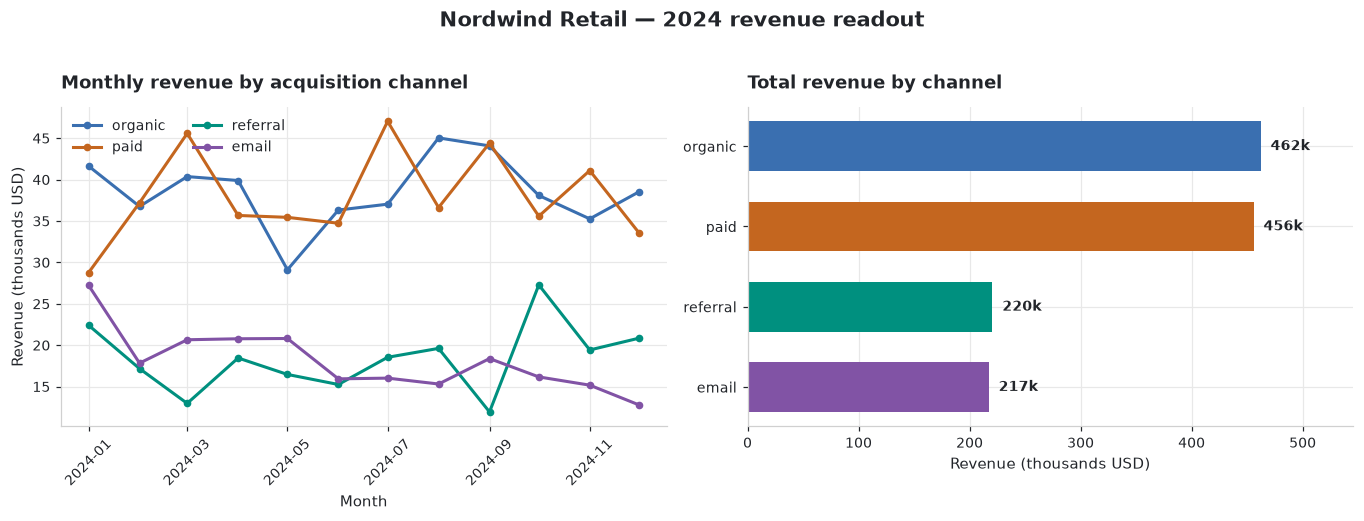

In [16]:
fig, (ax_trend, ax_share) = plt.subplots(1, 2, figsize=(12.5, 4.6))

# --- Left: monthly revenue by channel --------------------------------------
# Colour follows the channel (the entity), fixed regardless of rank — so a
# filtered view never repaints the survivors.
channel_order = list(channel_totals.index)
palette = dict(zip(channel_order,
                   [COLORS["primary"], COLORS["accent"], COLORS["teal"],
                    COLORS["purple"]],
                   strict=False))

for channel in channel_order:
    if channel in monthly.columns:
        ax_trend.plot(monthly.index, monthly[channel] / 1000,
                      marker="o", markersize=4, label=channel,
                      color=palette[channel])

ax_trend.set_title("Monthly revenue by acquisition channel")
ax_trend.set_ylabel("Revenue (thousands USD)")
ax_trend.set_xlabel("Month")
ax_trend.legend(ncol=2)
ax_trend.tick_params(axis="x", rotation=45)

# --- Right: total revenue share --------------------------------------------
bars = ax_share.barh(
    channel_totals.index[::-1],
    channel_totals["revenue"][::-1] / 1000,
    color=[palette[c] for c in channel_totals.index[::-1]],
    height=0.62,
)
ax_share.set_title("Total revenue by channel")
ax_share.set_xlabel("Revenue (thousands USD)")

# Direct labels instead of a second legend — the values are the message.
for bar, value in zip(bars, channel_totals["revenue"][::-1] / 1000, strict=True):
    ax_share.text(value, bar.get_y() + bar.get_height() / 2,
                  f"  {value:,.0f}k", va="center", fontsize=9,
                  fontweight="bold", color=COLORS["text"])
ax_share.set_xlim(0, (channel_totals["revenue"].max() / 1000) * 1.18)

fig.suptitle("Nordwind Retail — 2024 revenue readout", fontsize=13.5, y=1.02)
fig.tight_layout()
plt.show()

In [17]:
total_revenue = clean_orders["revenue"].sum()
top_channel = channel_totals.index[0]
top_share = channel_totals.loc[top_channel, "revenue"] / total_revenue

print("SUMMARY")
print("-" * 58)
print(f"Clean orders          : {len(clean_orders):,}")
print(f"Total revenue         : ${total_revenue:,.2f}")
print(f"Average order value   : ${clean_orders['revenue'].mean():,.2f}")
print(f"Median order value    : ${clean_orders['revenue'].median():,.2f}")
print(f"Largest channel       : {top_channel} ({top_share:.1%} of revenue)")
print(f"Weekend order share   : {clean_orders['is_weekend'].mean():.1%}")
print(f"Data quality          : {report.reject_rate:.2%} of rows rejected")

SUMMARY
----------------------------------------------------------
Clean orders          : 4,839
Total revenue         : $1,355,554.25
Average order value   : $280.13
Median order value    : $191.28
Largest channel       : organic (34.1% of revenue)
Weekend order share   : 28.5%
Data quality          : 5.12% of rows rejected


> [!NOTE]
> Median well below mean again — the right-skew from notebook 01. Reporting only
> the average order value would overstate what a typical order looks like.

## Step 7 — Test it

The pipeline is only trustworthy if its parts are tested. These cover the
categories from notebook 07: known answers, edge cases, no-mutation, and
invariants.

In [18]:
TEST_SOURCE = '''
"""Tests for the Nordwind pipeline's pure transformation functions."""
import numpy as np
import pandas as pd
import pytest


# --- the functions under test (copied so the file is self-contained) --------
def parse_amount(raw):
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return None
    text = str(raw).strip()
    if text.casefold() in {"", "n/a", "na", "-", "null", "none", "nan"}:
        return None
    normalised = text.replace(".", "").replace(",", ".")
    try:
        return float(normalised)
    except ValueError:
        return None


def clean_text_column(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\\s+", " ", regex=True)
        .str.casefold()
    )


# --- tests -----------------------------------------------------------------
class TestParseAmount:
    @pytest.mark.parametrize(
        ("raw", "expected"),
        [
            ("1.234,56", 1234.56),     # European thousands + decimal
            ("89,50", 89.50),
            ("0,01", 0.01),
            ("100", 100.0),            # no separators at all
            ("  42,00  ", 42.0),       # surrounding whitespace
        ],
    )
    def test_parses_european_format(self, raw, expected):
        assert parse_amount(raw) == pytest.approx(expected)

    @pytest.mark.parametrize(
        "token", ["N/A", "n/a", "", "  ", "-", "null", "NONE", "nan", None]
    )
    def test_missing_tokens_become_none(self, token):
        assert parse_amount(token) is None

    def test_unparseable_returns_none_not_zero(self):
        # The critical behaviour: garbage must NOT silently become 0.0,
        # which would corrupt every downstream sum.
        assert parse_amount("not-a-number") is None

    def test_negative_amounts_are_preserved(self):
        # Refunds are legitimate negative values; parsing must not drop them.
        assert parse_amount("-50,00") == pytest.approx(-50.0)


class TestCleanTextColumn:
    def test_trims_collapses_and_lowercases(self):
        s = pd.Series(["  Organic ", "PAID", "re  ferral"])
        result = clean_text_column(s).tolist()
        assert result == ["organic", "paid", "re ferral"]

    def test_does_not_mutate_the_input(self):
        s = pd.Series(["  Organic "])
        original = s.copy()
        clean_text_column(s)
        assert s.equals(original)

    def test_handles_nulls(self):
        s = pd.Series(["Organic", None])
        result = clean_text_column(s)
        assert result.iloc[0] == "organic"
        assert pd.isna(result.iloc[1])


class TestPipelineInvariants:
    """Properties the whole pipeline must satisfy, whatever the input."""

    def test_revenue_equals_amount_times_quantity(self):
        df = pd.DataFrame({"amount": [10.0, 2.5], "quantity": [3, 4]})
        revenue = (df["amount"] * df["quantity"]).round(2)
        assert revenue.tolist() == [30.0, 10.0]

    def test_reject_rate_is_zero_for_empty_input(self):
        # Guard against ZeroDivisionError on an empty run.
        rows_read, rows_written = 0, 0
        rate = 0.0 if rows_read == 0 else 1 - rows_written / rows_read
        assert rate == 0.0
'''

with tempfile.TemporaryDirectory() as tmpdir:
    test_path = Path(tmpdir) / "test_nordwind_pipeline.py"
    test_path.write_text(TEST_SOURCE)

    completed = subprocess.run(
        [sys.executable, "-m", "pytest", str(test_path),
         "-v", "--no-header", "-p", "no:cacheprovider"],
        capture_output=True,
        text=True,
    )

for line in completed.stdout.splitlines():
    if "::" in line or " passed" in line or " failed" in line:
        print(line.split("/")[-1] if "::" in line else line)

test_nordwind_pipeline.py::TestParseAmount::test_parses_european_format[1.234,56-1234.56] PASSED [  4%]
test_nordwind_pipeline.py::TestParseAmount::test_parses_european_format[89,50-89.5] PASSED [  9%]
test_nordwind_pipeline.py::TestParseAmount::test_parses_european_format[0,01-0.01] PASSED [ 14%]
test_nordwind_pipeline.py::TestParseAmount::test_parses_european_format[100-100.0] PASSED [ 19%]
test_nordwind_pipeline.py::TestParseAmount::test_parses_european_format[  42,00  -42.0] PASSED [ 23%]
A] PASSED [ 28%]
a] PASSED [ 33%]
test_nordwind_pipeline.py::TestParseAmount::test_missing_tokens_become_none[] PASSED [ 38%]
test_nordwind_pipeline.py::TestParseAmount::test_missing_tokens_become_none[  ] PASSED [ 42%]
test_nordwind_pipeline.py::TestParseAmount::test_missing_tokens_become_none[-] PASSED [ 47%]
test_nordwind_pipeline.py::TestParseAmount::test_missing_tokens_become_none[null] PASSED [ 52%]
test_nordwind_pipeline.py::TestParseAmount::test_missing_tokens_become_none[NONE] PASSED [ 57

## Step 8 — Verify the output is loadable and correct

The last check: read back what we wrote, exactly as a downstream consumer would.

In [19]:
verification = pd.read_parquet(CONFIG.output_path)

checks = {
    "row count matches": len(verification) == len(clean_orders),
    "dtypes preserved": verification.dtypes.equals(clean_orders.dtypes),
    "no null revenue": not verification["revenue"].isna().any(),
    "all amounts positive": (verification["amount"] > 0).all(),
    "all quantities positive": (verification["quantity"] > 0).all(),
    "channels are all valid": set(verification["channel"].unique())
                              <= CONFIG.valid_channels,
    "no duplicate order rows": not verification.duplicated().any(),
    "revenue reconciles": np.isclose(
        verification["revenue"].sum(),
        (verification["amount"] * verification["quantity"]).sum(),
        rtol=1e-6,
    ),
}

for name, passed in checks.items():
    print(f"  {'✔' if passed else '✘'}  {name}")

print(f"\n{'ALL CHECKS PASSED' if all(checks.values()) else 'SOME CHECKS FAILED'}")

# When a schema check fails, "the dtypes differ" is useless on its own — show
# exactly which column drifted and how. Build this into your own pipelines.
if not checks["dtypes preserved"]:
    drift = pd.DataFrame({
        "written": clean_orders.dtypes.astype(str),
        "read back": verification.dtypes.astype(str),
    })
    print("\nColumns whose dtype changed:")
    print(drift.loc[drift["written"] != drift["read back"]])

  ✔  row count matches
  ✔  dtypes preserved
  ✔  no null revenue
  ✔  all amounts positive
  ✔  all quantities positive
  ✔  channels are all valid
  ✔  no duplicate order rows
  ✔  revenue reconciles

ALL CHECKS PASSED


## Step 9 — Prove the quality gate works

A safety net you have never seen fire is not a safety net. Force it.

In [20]:
strict_config = PipelineConfig(
    orders_path=ORDERS_PATH,
    customers_path=CUSTOMERS_PATH,
    output_path=PROCESSED_DIR / "should_not_exist.parquet",
    max_reject_rate=0.001,        # far stricter than the real reject rate
)

try:
    run_pipeline(strict_config)
except DataQualityError as exc:
    print(f"\n✔ Gate fired as designed:\n  DataQualityError: {exc}")
    print(f"  Output written? {strict_config.output_path.exists()}")

13:07:21 | INFO     | nordwind.extract       | Read 5100 raw order rows


13:07:21 | INFO     | nordwind.extract       | Read 800 customer records (exported 2024-12-31T23:59:59Z)


13:07:21 | INFO     | nordwind.pipeline      | Removed 100 duplicate rows


13:07:21 | INFO     | nordwind.pipeline      | Parsed types; 150 amount(s) unparseable


13:07:21 | WARNING  | nordwind.pipeline      | Rejected 150 row(s): amount missing or unparseable


13:07:21 | WARNING  | nordwind.pipeline      | Rejected 11 row(s): quantity not positive


13:07:21 | WARNING  | nordwind.pipeline      | 24 order(s) reference an unknown customer



✔ Gate fired as designed:
  DataQualityError: reject rate 5.1% exceeds the 0% threshold — refusing to publish
  Output written? False


## Your turn — extensions

The pipeline works. Now make it better. Each of these is a real requirement you
would receive on the job.

### Extension 1 — Promote code into `dstoolkit` ⭐

Move `parse_amount` and `clean_text_column` into `src/dstoolkit/cleaning.py`,
export them from `__init__.py`, add tests in `tests/test_cleaning.py`, and
import them back here. This is the promotion loop from notebook 01 — do it once
and it becomes automatic.

### Extension 2 — Stream the input ⭐⭐

Rewrite `extract_orders` to process the CSV in chunks (`chunksize=1000`) so the
pipeline can handle a file larger than RAM. Verify the totals are unchanged.

### Extension 3 — A rejected-rows report ⭐⭐

Instead of silently discarding bad rows, write them to
`data/processed/rejected_rows.parquet` with a `rejection_reason` column. Data
engineers need this to fix the upstream system.

### Extension 4 — Idempotency ⭐⭐

Running the pipeline twice should produce a byte-identical output. Verify it,
and use the `atomic_write` pattern from notebook 06 so a crash mid-write cannot
corrupt the published table.

### Extension 5 — A `@monitored` decorator ⭐⭐⭐

Write a decorator that logs each step's name, duration, and input/output row
counts, then apply it to every transformation function. You have just built a
miniature version of what Airflow and Dagster do.

### Extension 6 — Schema validation ⭐⭐⭐

Replace the manual checks with a declarative schema (a dict of column → expected
dtype and constraints) and one generic validator. Compare your design with
`pandera`, which does exactly this professionally.

## What you built

A pipeline that:

- reads badly-formatted sources **defensively**, declaring their quirks explicitly;
- separates a thin **impure shell** (I/O) from a **pure core** (transformations);
- carries its configuration in a **frozen dataclass** so nothing drifts mid-run;
- **counts and logs** every row it drops, with the reason;
- **refuses to publish** output it cannot vouch for;
- is **tested**, including the edge cases where the real bugs live;
- writes typed, compressed **Parquet** that reloads exactly as written.

That is a genuinely professional shape for a data pipeline. Every later module
in this course plugs into it: Module 03 replaces the transformations with
richer pandas, Module 10 adds feature engineering, Module 21 adds experiment
tracking, and Module 22 puts a model behind an API.

## Module 01 complete — self-assessment

You are ready for Module 02 when you can answer these without looking them up:

- [ ] Why does `b = a` then `b.append(1)` sometimes change `a`?
- [ ] Why is `0.1 + 0.2 == 0.3` `False`, and what should you write instead?
- [ ] Why is `x in my_set` faster than `x in my_list`, and by how much?
- [ ] What is the difference between a list comprehension and a generator expression?
- [ ] What does `def f(x=[])` do, and why is it a bug?
- [ ] When would you use `@dataclass` rather than writing `__init__`?
- [ ] Why is `except Exception:` usually wrong?
- [ ] Why should a pipeline use `logging` rather than `print`?
- [ ] What makes Parquet a better choice than CSV for a 5 GB dataset?
- [ ] Why must `assert` never be used to validate incoming data?

---

**Next:** Module 02 — NumPy & Numerical Computing. You will learn why
`sum(my_list)` is 50× slower than `arr.sum()`, and how vectorisation actually
works underneath.